# Diabetes Status Classification | Consolidated ML + BDA

**Undergraduate group coursework, Lebanese American University.** This reproducible portfolio notebook consolidates the original Machine Learning and Business Data Analytics notebooks. Team acknowledgments and unmodified source notebooks are available in `ACKNOWLEDGMENTS.md` and `archive/`.

**Scope:** binary *diabetes status* classification (not future-onset prediction or a clinical diagnostic tool).

## 1. Dataset inspection and preparation

The source file includes 520 rows and multiple repeated records. The shared cleaned dataset removes identical rows *before* train/test splitting to prevent identical records from appearing in both partitions. The original notebooks applied preprocessing and evaluation differently; the consolidated pipeline standardizes these steps.

In [1]:
from IPython.display import display, Image
import pandas as pd
from src.modeling import load_data, FEATURES
data, profile = load_data()
print(profile)
display(data.head())
display(data["class"].map({0:"Negative",1:"Positive"}).value_counts().rename("Count"))

{'raw_rows': 520, 'duplicate_rows': 269, 'unique_rows': 251}


,Age,Gender,Polyuria,Polydipsia,sudden weight loss,weakness,Polyphagia,Genital thrush,visual blurring,Itching,Irritability,delayed healing,partial paresis,muscle stiffness,Alopecia,Obesity,class
0,40,1,0,1,0,1,0,0,0,1,0,1,0,1,1,1,1
1,58,1,0,0,0,1,0,0,1,0,0,0,1,0,1,0,1
2,41,1,1,0,0,1,1,0,0,1,0,1,0,1,1,0,1
3,45,1,0,0,1,1,1,1,0,1,0,1,0,0,0,0,1
4,60,1,1,1,1,1,1,0,1,1,1,1,1,1,1,1,1


class
Positive    173
Negative     78
Name: Count, dtype: int64

## 2. Exploratory visualizations

The plots summarize the number of duplicate rows and the class imbalance after deduplication. Missing values are rejected rather than filled without examination; the original supplied data has no missing values.

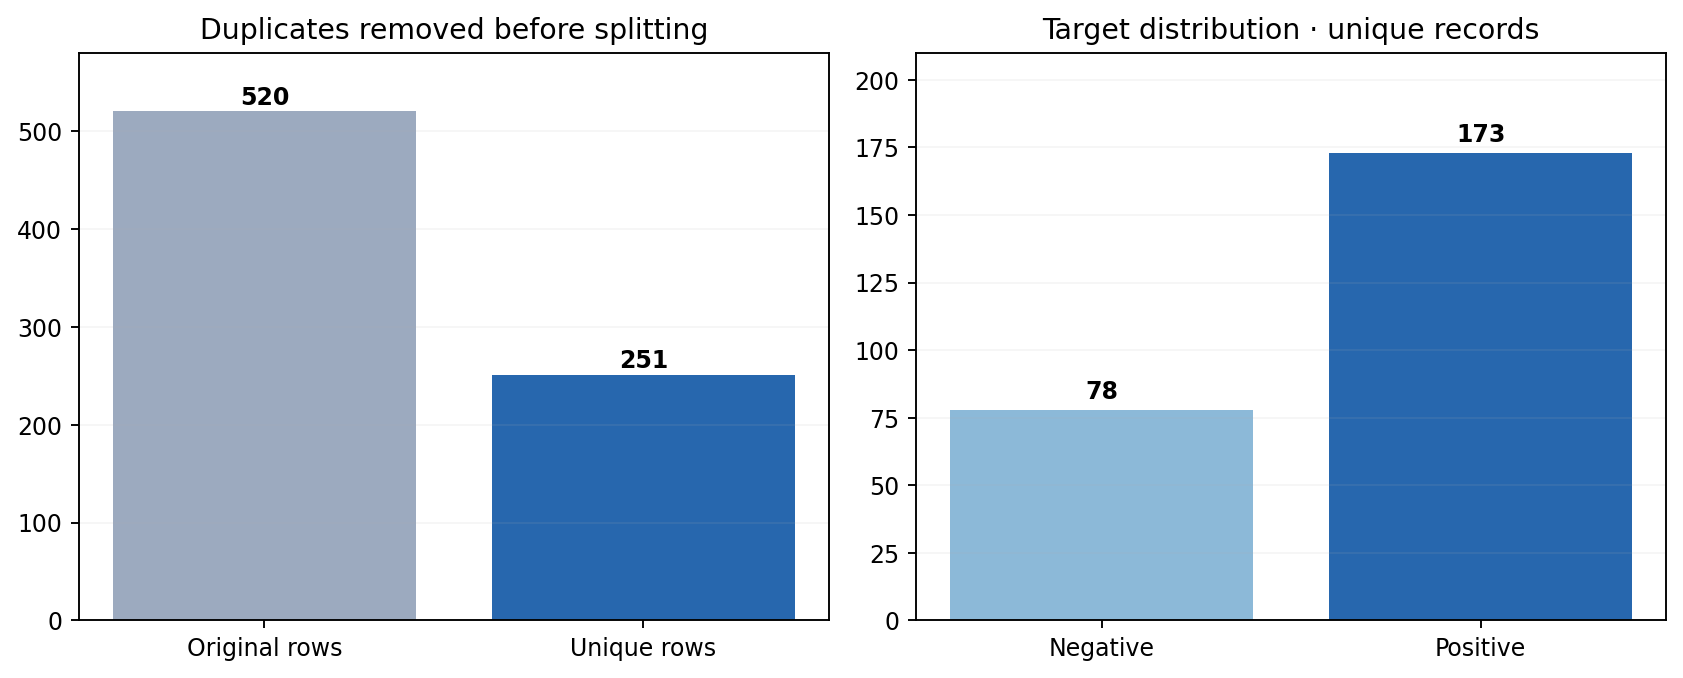

Features most correlated with the label: Polyuria              0.620992
Polydipsia            0.594615
sudden weight loss    0.372554
partial paresis       0.360288
Polyphagia            0.316808
Irritability          0.268806
visual blurring       0.199228
Genital thrush        0.191117
Name: class, dtype: float64


In [2]:
display(Image(filename="docs/images/dataset-profile.png", width=850))

corr = data.corr(numeric_only=True)["class"].drop("class").sort_values(ascending=False)
print("Features most correlated with the label:", corr.head(8))

## 3. Model comparison

The five approaches reflect the original coursework (Logistic Regression, Decision Tree, Random Forest, soft-voting ensemble) plus a corrected resampling pipeline using `SMOTENC` for one numeric and 15 categorical features. Each candidate is assessed with **stratified five-fold cross-validation on training data only**. The final model is selected by mean cross-validation balanced accuracy. The holdout set is used only to report performance.

,model,cv_balanced_accuracy_mean,accuracy,balanced_accuracy,recall_positive,f1_positive,roc_auc
2,Random Forest,0.898,0.902,0.895,0.914,0.928,0.962
4,Random Forest + SMOTENC,0.894,0.922,0.926,0.914,0.941,0.959
3,Soft Voting Ensemble,0.882,0.863,0.883,0.829,0.892,0.950
0,Logistic Regression,0.881,0.804,0.823,0.771,0.844,0.920
1,Decision Tree,0.850,0.765,0.812,0.686,0.800,0.874


Selected by training CV: Random Forest


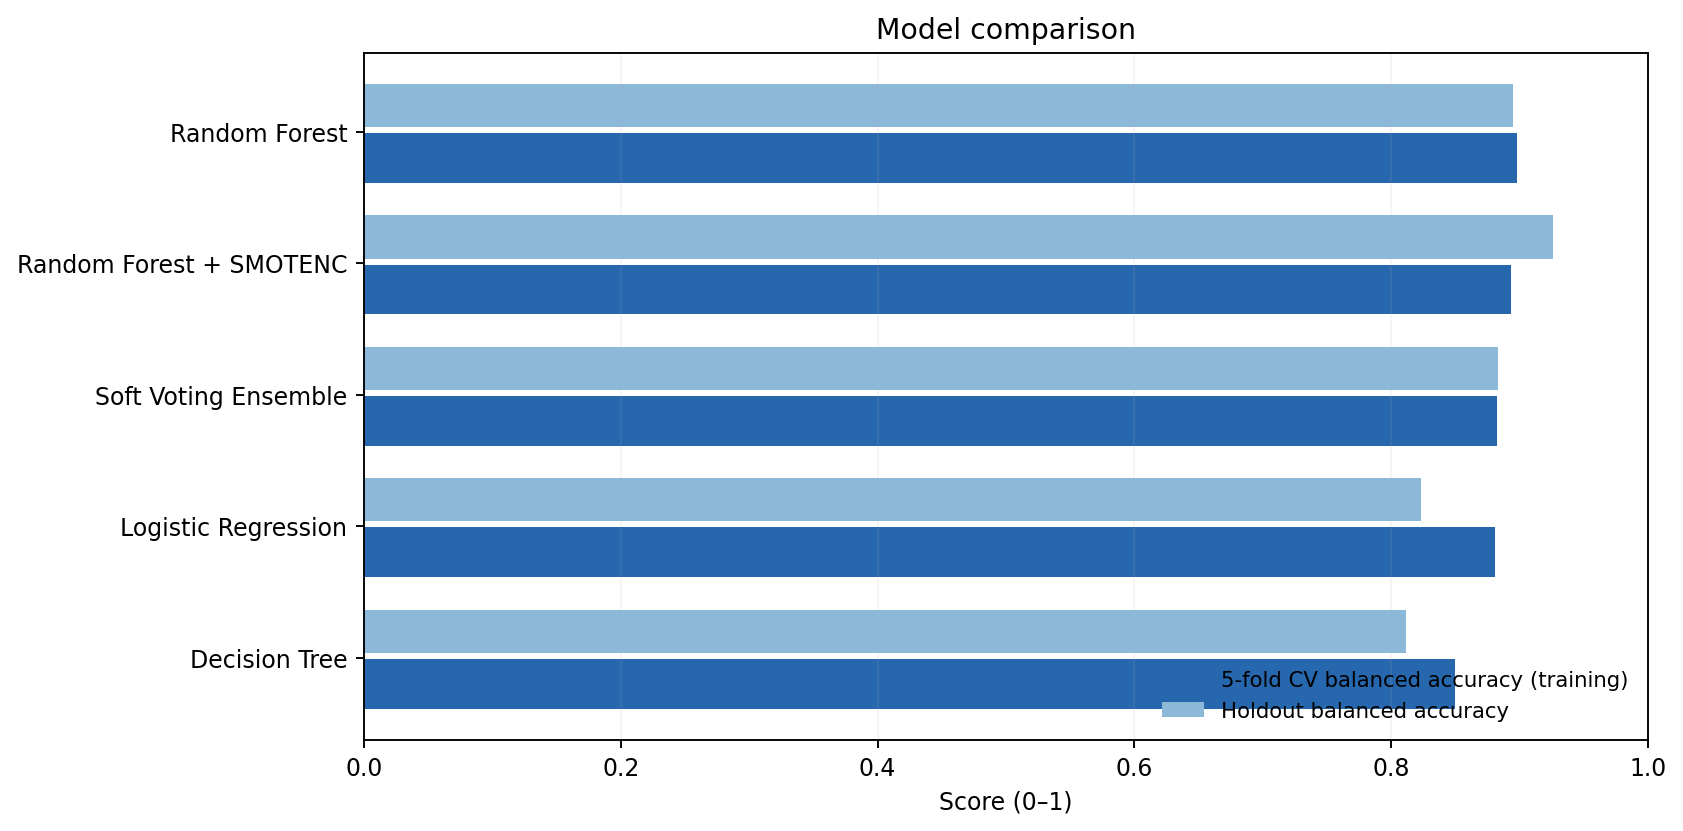

In [3]:
import json
from pathlib import Path
import pandas as pd
metadata = json.loads(Path("models/metadata.json").read_text())
results = pd.DataFrame(metadata["model_results"])
cols = ["model", "cv_balanced_accuracy_mean", "accuracy", "balanced_accuracy", "recall_positive", "f1_positive", "roc_auc"]
display(results[cols].sort_values("cv_balanced_accuracy_mean", ascending=False).round(3))
print("Selected by training CV:", metadata["selected_model"])
display(Image(filename="docs/images/model-comparison.png", width=820))

## 4. Interpreting the selected classifier

The confusion matrix and ROC curve refer to the fixed held-out test set. Permutation feature importance indicates each input's contribution to holdout balanced accuracy, but it is **not a causal or clinical explanation**.

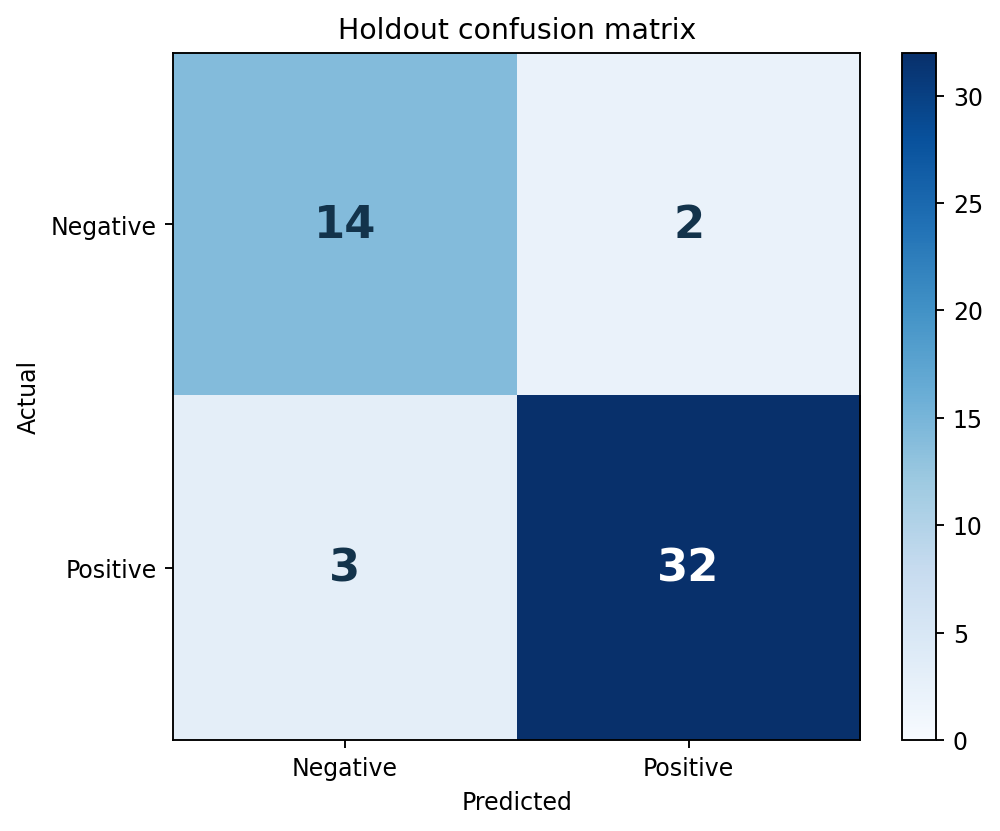

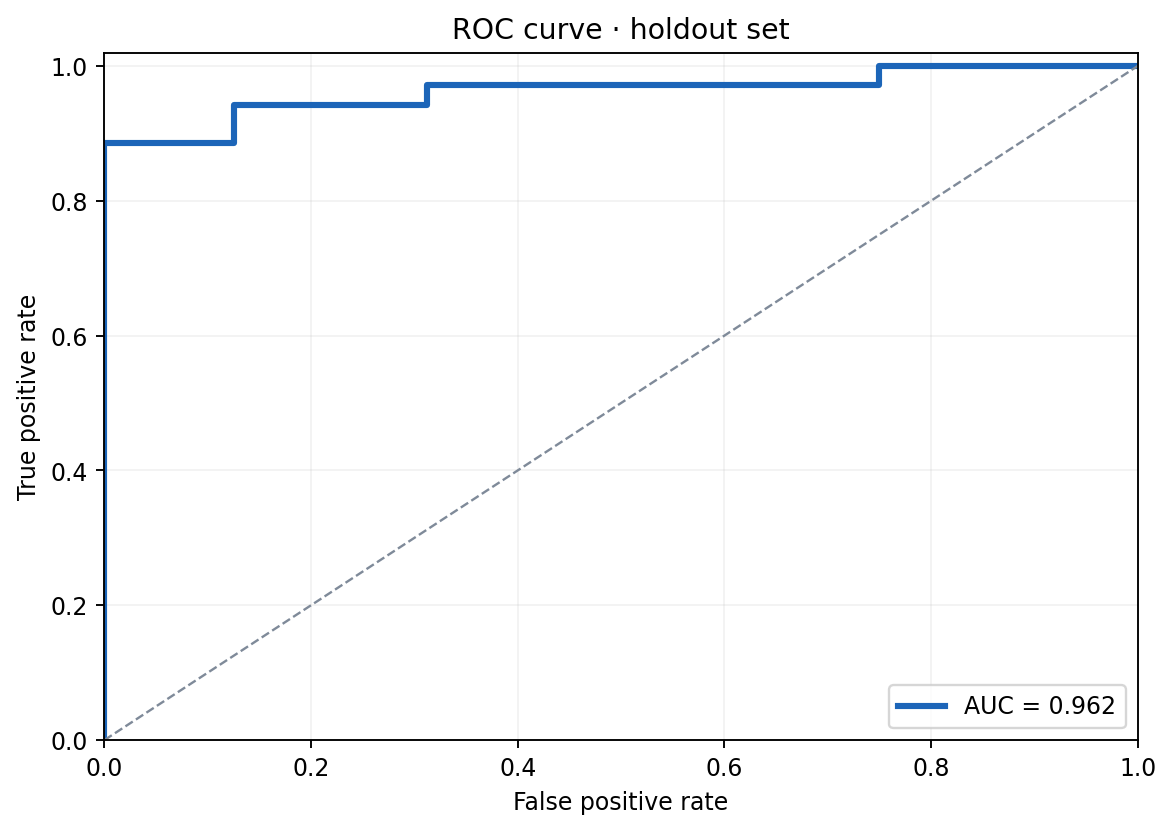

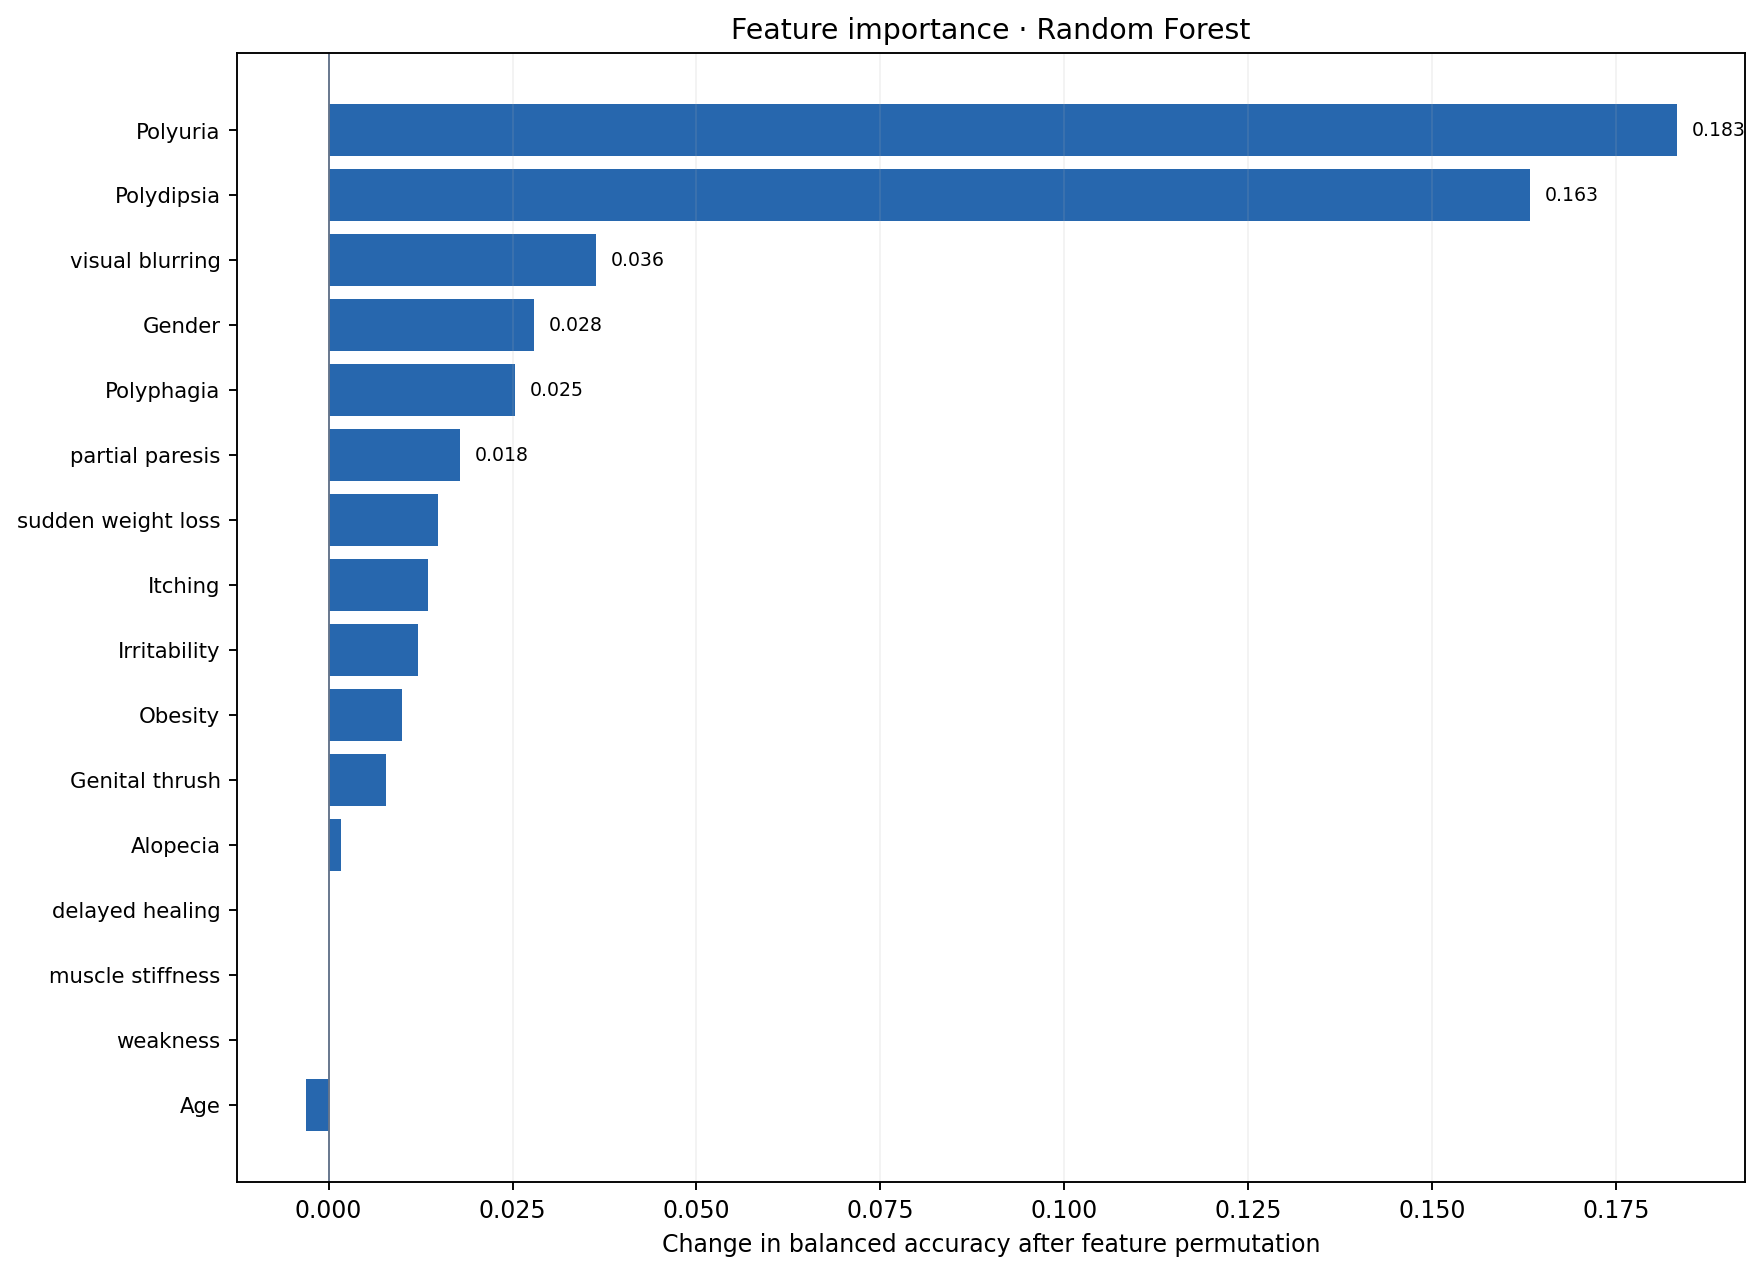

In [4]:
display(Image(filename="docs/images/confusion-matrix.png", width=520))
display(Image(filename="docs/images/roc-curve.png", width=600))
display(Image(filename="docs/images/feature-importance.png", width=850))

## 5. Local inference example

Use the exact column ordering and category encoding that the web interface uses. The example is synthetic and demonstrates model behavior only.

In [5]:
from src.predict import predict_sample
print(predict_sample())

{'predicted_class': 'Positive', 'probability_positive': 0.9509494949494948}


## 6. Reproducing the pipeline

From the repository root, run `python train.py` to regenerate the saved model, evaluation table, and figure assets. Then run `python app.py` to open the interactive Flask demo at http://127.0.0.1:5000.

**Limitations:** the sample is small and duplication-heavy, source labels represent diabetes status, and no independent external or clinical validation was performed. See the README for project background and credit.